# Heat Flux Analysis

Time-series analysis of the variable HeatFlux_st extracted from 800 runs of GX.

In [1]:
import src.pugs as pugs

import numpy as np
import pandas as pd
import scipy.stats as st
import matplotlib.pyplot as plt

import os
from glob import glob

In [2]:
def process_folder(foler, exp_id, trim_variable, variable=None, output_file=None, method="std", **kwargs):
    # Get all experiment folders matching exp_id
    exp_folders = os.path.join(foler, f"{exp_id}_theta0_*_zeta0_*")
    folders = sorted(glob(exp_folders))

    # Process each folder and collect results
    results = []
    for f in folders:
        # Process individual GX file
        file = os.path.join(f, "gx.out.nc")
        output = pugs.process_file(trim_variable, file, variable=variable, method=method, **kwargs)

        # Extract experiment identification
        parts = os.path.basename(f).split("_")
        exp_info = {"id": parts[0], "theta": parts[2], "zeta": parts[4]}

        # Skip if output is None
        if output is None:
            results.append({**exp_info, "file": file})
            continue

        # Read output CSV and extract results
        df = pd.read_csv(output)
        cols = df.columns
        for row in df.itertuples(index=False):
            results.append({**exp_info, **dict(zip(cols, row))})

        # Remove temporary output file
        os.remove(output)

    # Prepare output CSV
    if output_file is None:
        output_file = f"{exp_id}_{trim_variable}_{method}.csv"
        if exp_id == "*":
            output_file = f"all_{trim_variable}_{method}.csv"

    # Return results as DataFrame and save to CSV
    df = pd.DataFrame(results)
    output = pugs.export_file(df, output_file, format="csv")

    return output

In [3]:
folder = "/Users/zacharygottlieb/local/stellarator/data/20241119-01-008_200_configs"
exp_id = "000089"
variable = "HeatFlux_st"
method = "linreg"

In [4]:
output = process_folder(folder, exp_id, trim_variable=variable, variable=variable, method=method)
df = pd.read_csv(output)
df.head()

,id,theta,zeta,file,trim_variable,variable,method,start_time,mean,median,...,var,sem,cv,mad,min,max,ptp,q1,q3,iqr
0,89,0.00,0.00,/Users/zacharygottlieb/local/stellarator/data/...,HeatFlux_st,HeatFlux_st,linreg,30.984904,27.757189,27.443577,...,36.304752,0.189125,0.217073,3.717724,16.338631,51.386887,35.048256,23.402204,30.778850,7.376646
1,89,0.00,1.57,/Users/zacharygottlieb/local/stellarator/data/...,HeatFlux_st,HeatFlux_st,linreg,40.158300,6.684722,6.654868,...,0.638503,0.027185,0.119536,0.516102,4.649896,9.482733,4.832837,6.113927,7.163241,1.049313
2,89,3.14,0.00,/Users/zacharygottlieb/local/stellarator/data/...,HeatFlux_st,HeatFlux_st,linreg,35.718684,8.140309,7.780753,...,2.970055,0.063353,0.211710,0.841985,5.275638,16.793032,11.517394,7.066919,8.867213,1.800294
3,89,3.14,1.57,/Users/zacharygottlieb/local/stellarator/data/...,HeatFlux_st,HeatFlux_st,linreg,40.218501,1.109290,1.102740,...,0.012346,0.003271,0.100167,0.076695,0.843765,1.483123,0.639358,1.032088,1.180510,0.148421


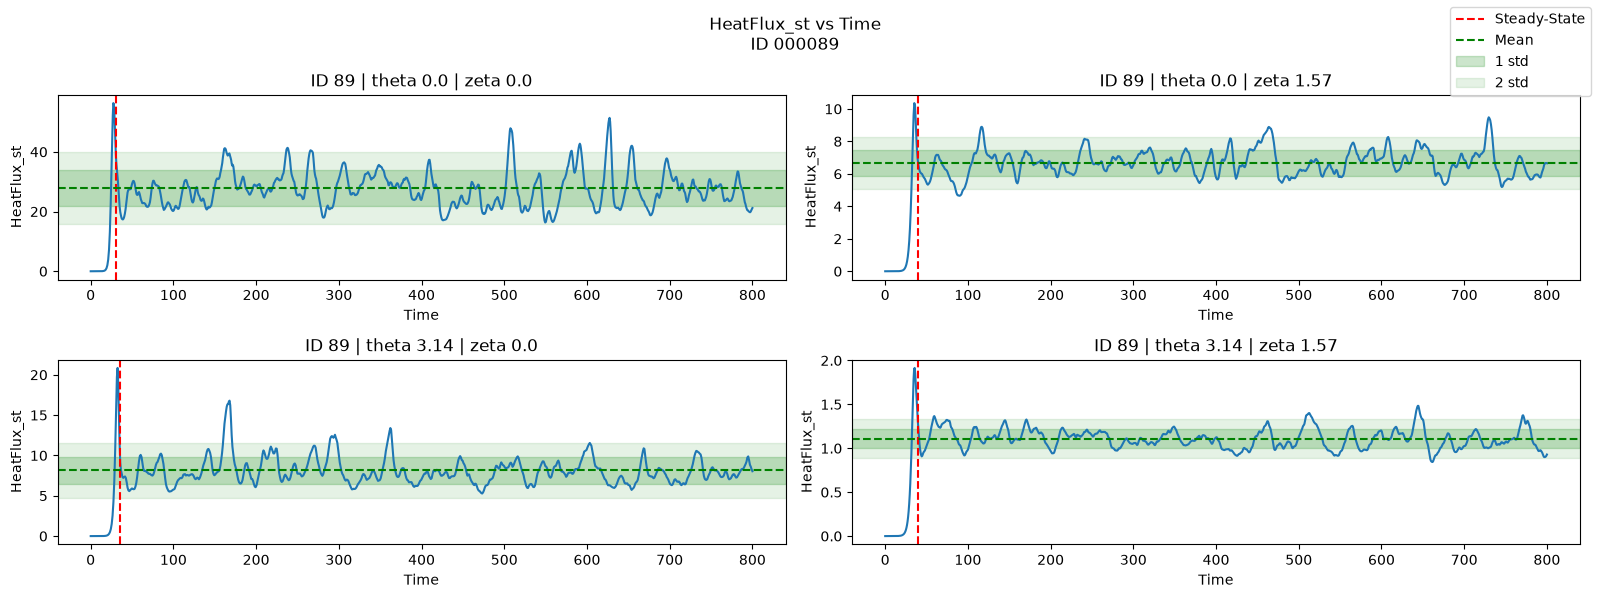

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16,6))

for i, ax in enumerate(axes.flatten()):
    df_i = pugs.load_file(df.iloc[i]["file"], variable)
    t = df_i["time"].to_numpy()
    x = df_i[variable].to_numpy()

    ax.plot(t, x)
    ax.axvline(df.iloc[i]["start_time"], color='red', linestyle='--', label="Steady-State")

    ax.axhline(df.iloc[i]["mean"], color='green', linestyle='--', label="Mean")
    ax.axhspan(df.iloc[i]["mean"] - df.iloc[i]["std"], df.iloc[i]["mean"] + df.iloc[i]["std"], color='green', alpha=0.2, label="1 std")
    ax.axhspan(df.iloc[i]["mean"] - 2 * df.iloc[i]["std"], df.iloc[i]["mean"] + 2 * df.iloc[i]["std"], color='green', alpha=0.1, label="2 std")

    ax.set_title(f"ID {df.iloc[i]['id']} | theta {df.iloc[i]['theta']} | zeta {df.iloc[i]['zeta']}")
    ax.set_xlabel("Time")
    ax.set_ylabel(variable)

fig.suptitle(f"{variable} vs Time\nID {exp_id}")
handles, labels = axes.flatten()[-1].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right')

plt.tight_layout()
plt.show()

In [ ]:
process_folder(folder, "*", trim_variable=variable, variable=variable, method=method)

In [6]:
df_raw = pd.read_csv(f"all_{variable}_{method}.csv")
df = df_raw[df_raw["start_time"].notnull()]
print(f"{df.shape[0]} runs with steady-state found")

df_failed = df_raw[df_raw["start_time"].isnull()]
failed_init = []
failed_algo = []

for row in df_failed.itertuples(index=False):
    df_i = pugs.load_file(row.file, variable)
    x = df_i[variable].to_numpy()
    if np.max(x) < 1e-4:
        failed_init.append(row)
    else:
        failed_algo.append(row)

df_failed_init = pd.DataFrame(failed_init)
df_failed_algo = pd.DataFrame(failed_algo)

print(f"{df_failed_init.shape[0]} runs failed to initialize")
print(f"{df_failed_algo.shape[0]} runs failed to reach steady-state")

517 runs with steady-state found
269 runs failed to initialize
14 runs failed to reach steady-state


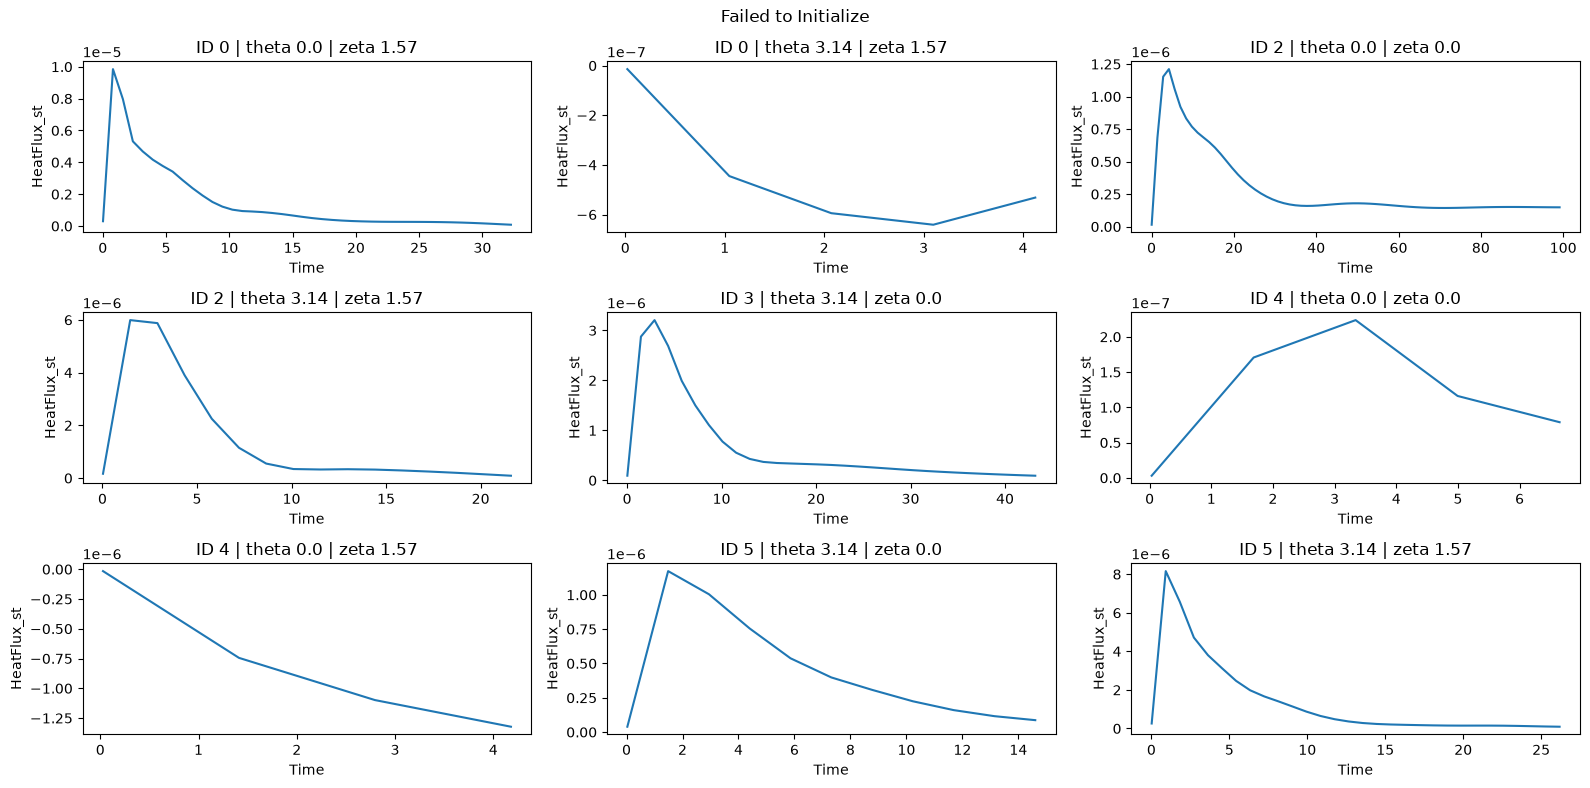

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(16,8))

for i, ax in enumerate(axes.flatten()):
    df_i = pugs.load_file(df_failed_init.iloc[i]["file"], variable)
    t = df_i["time"].to_numpy()
    x = df_i[variable].to_numpy()

    ax.plot(t, x)

    ax.set_title(f"ID {df_failed_init.iloc[i]['id']} | theta {df_failed_init.iloc[i]['theta']} | zeta {df_failed_init.iloc[i]['zeta']}")
    ax.set_xlabel("Time")
    ax.set_ylabel(variable)

fig.suptitle(f"Failed to Initialize")

plt.tight_layout()
plt.show()

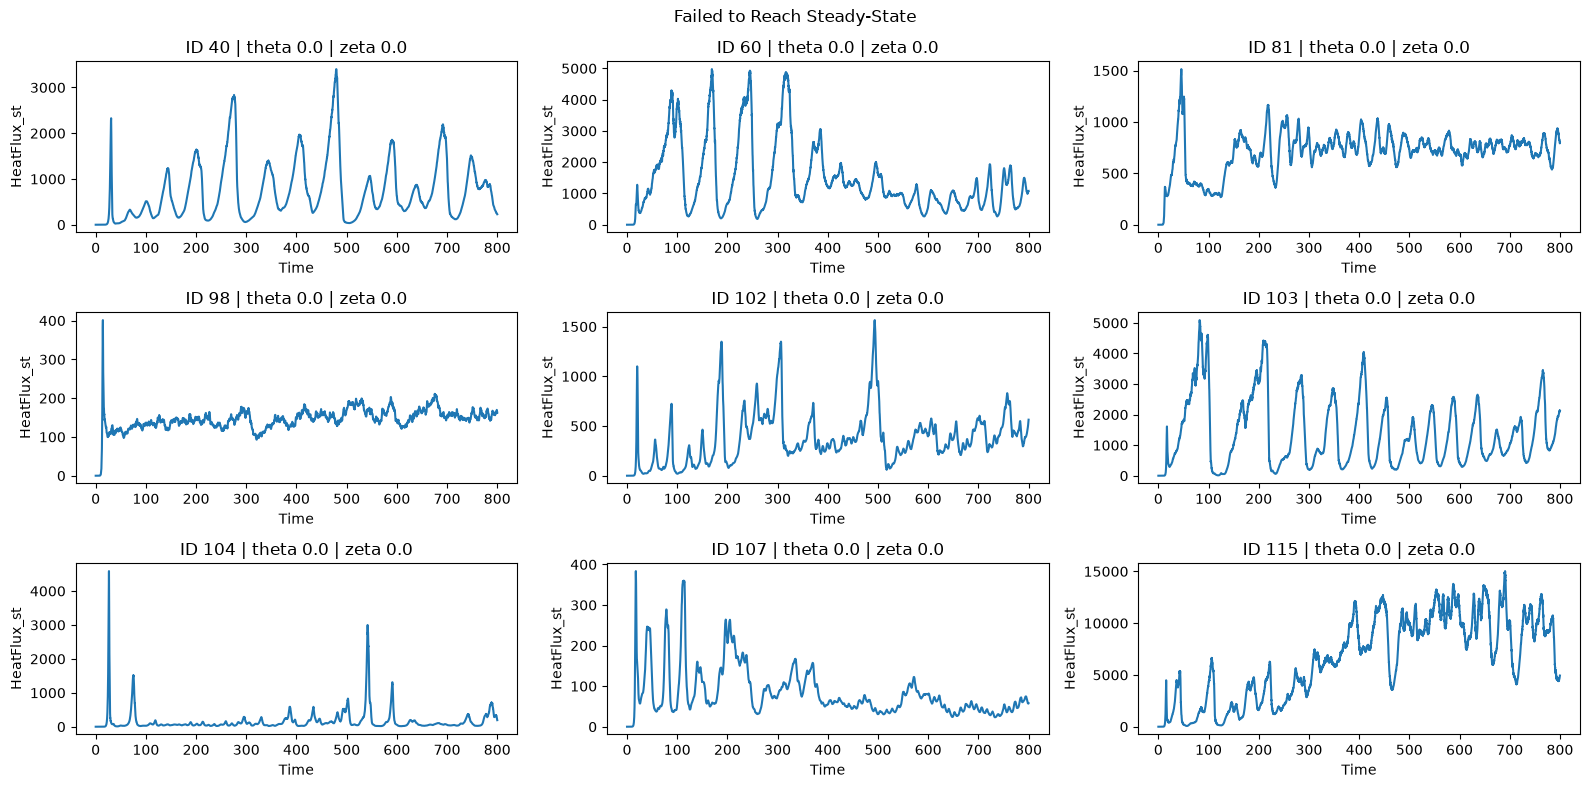

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(16,8))

for i, ax in enumerate(axes.flatten()):
    df_i = pugs.load_file(df_failed_algo.iloc[i]["file"], variable)
    t = df_i["time"].to_numpy()
    x = df_i[variable].to_numpy()

    ax.plot(t, x)

    ax.set_title(f"ID {df_failed_algo.iloc[i]['id']} | theta {df_failed_algo.iloc[i]['theta']} | zeta {df_failed_algo.iloc[i]['zeta']}")
    ax.set_xlabel("Time")
    ax.set_ylabel(variable)

fig.suptitle(f"Failed to Reach Steady-State")

plt.tight_layout()
plt.show()

In [9]:
logx = np.log(df["start_time"])
logy = np.log(df["mean"])

slope, intercept, r_val, p_val, std_err = st.linregress(logx, logy)

print(f"Mean {variable} = {np.exp(intercept):.5f} * (Time to Steady-State)^({slope:.5f})")
print(f"R-squared: {r_val**2:.5f}")

Mean HeatFlux_st = 2536.42827 * (Time to Steady-State)^(-1.47043)
R-squared: 0.68083


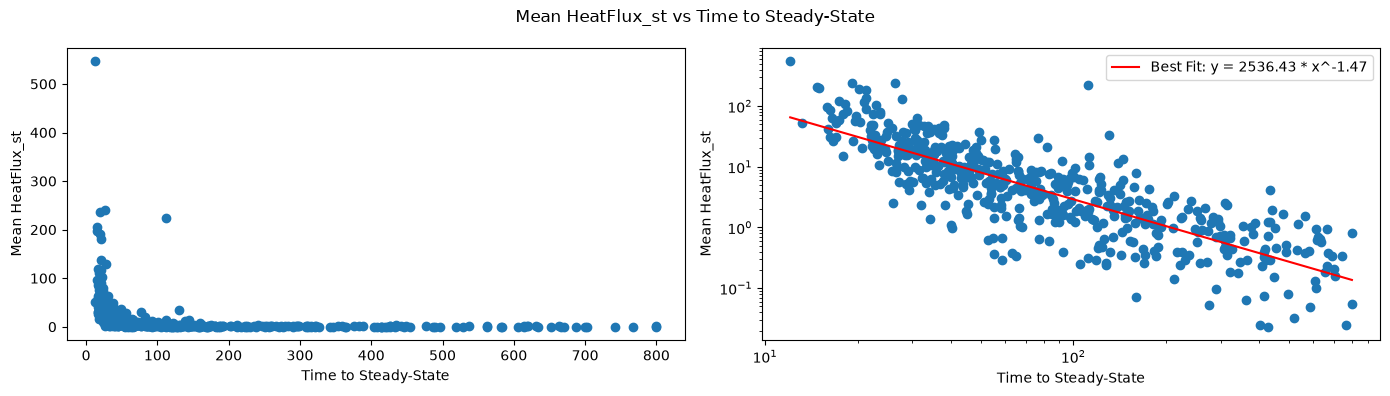

In [10]:
xline = np.linspace(df["start_time"].min(), df["start_time"].max(), 400)
yline = np.exp(intercept) * xline**slope

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for i, ax in enumerate(axes.flatten()):
    ax.scatter(df["start_time"], df["mean"])
    ax.set_xlabel("Time to Steady-State")
    ax.set_ylabel(f"Mean {variable}")

    if i == 1:
        ax.plot(xline, yline, color='red', label=f"Best Fit: y = {np.exp(intercept):.2f} * x^{slope:.2f}")
        ax.set_xscale("log")
        ax.set_yscale("log")

fig.suptitle(f"Mean {variable} vs Time to Steady-State")

plt.legend()
plt.tight_layout()
plt.show()

In [11]:
df = df.dropna(subset=["std", "mean"])
slope, intercept, r_val, p_val, std_err = st.linregress(df["std"], df["mean"])

print(f"Mean {variable} = {slope:.5f} * (Standard Deviation) + {intercept:.5f}")
print(f"R-squared: {r_val**2:.5f}")

Mean HeatFlux_st = 2.66973 * (Standard Deviation) + 4.48841
R-squared: 0.90875


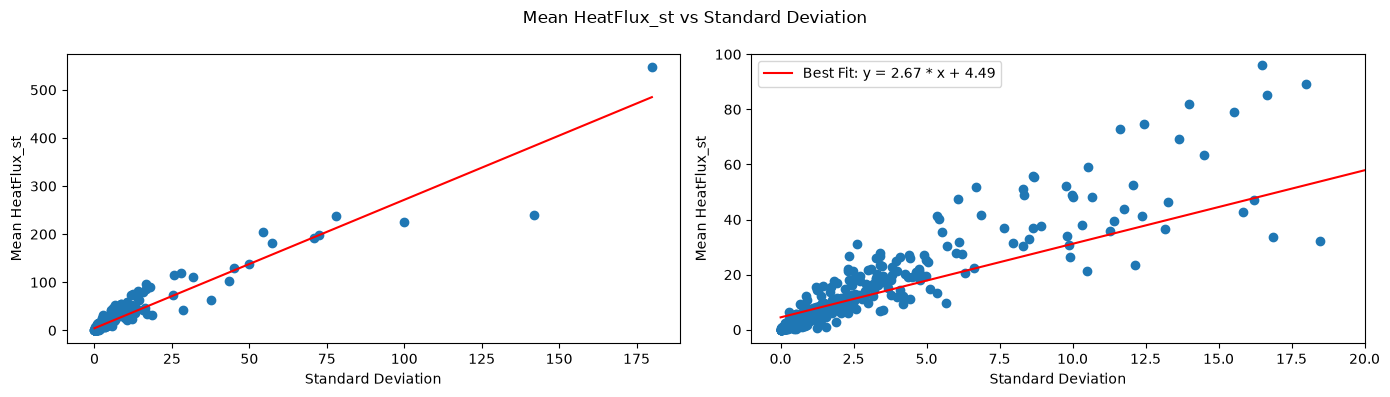

In [12]:
xline = np.linspace(df["std"].min(), df["std"].max(), 400)
yline = slope * xline + intercept

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for i, ax in enumerate(axes.flatten()):
    ax.scatter(df["std"], df["mean"])
    ax.set_xlabel("Standard Deviation")
    ax.set_ylabel(f"Mean {variable}")
    ax.plot(xline, yline, color='red', label=f"Best Fit: y = {slope:.2f} * x + {intercept:.2f}")

    if i == 1:
        ax.set_xlim(-1, 20)
        ax.set_ylim(-5, 100)

fig.suptitle(f"Mean {variable} vs Standard Deviation")

plt.legend()
plt.tight_layout()
plt.show()